# 03 小兔鲜儿 - 推荐模块


本篇承接 02 首页的热门推荐入口，按照配套讲义 `rabbit-shop/03-推荐模块.md` 整理，主要实现**动态推荐页、Tabs 交互和多个 Tab 的独立分页**。

四种推荐类型的页面布局相同，封面、标题、Tab 和商品数据不同，因此使用同一个 `pages/hot/hot` 页面，通过参数选择接口。请求继续复用 01 的 `http<T>`，分页结果继续复用 02 的 `PageResult<T>`。

资料来自[课程网盘](https://pan.baidu.com/s/1uhQQvqs9ESRvhEvgzgSUWQ?pwd=9988)，提取码 `9988`，配套包为 `02-笔记.rar`。本篇的两张教学图片直接内嵌在 Notebook 中。

| 文件 | 本篇职责 |
| --- | --- |
| `src/pages/index/components/HotPanel.vue` | 从首页传递推荐类型 `type` |
| `src/pages/hot/hot.vue` | 标题、封面、Tabs、商品列表与触底分页 |
| `src/pages.json` | 注册推荐页面 |
| `src/services/hot.ts` | 统一封装四种推荐接口 |
| `src/types/hot.d.ts` | 推荐页和子类数据类型 |
| `src/types/global.d.ts` | 通用商品类型与已有分页类型 |
| `src/types/home.d.ts` | 让猜你喜欢复用通用商品类型 |


## 动态获取数据

推荐页要解决两件事：根据首页传入的类型选择数据源，再把封面、Tab 和商品列表渲染出来。

四个入口共用布局，页面不必复制四份：

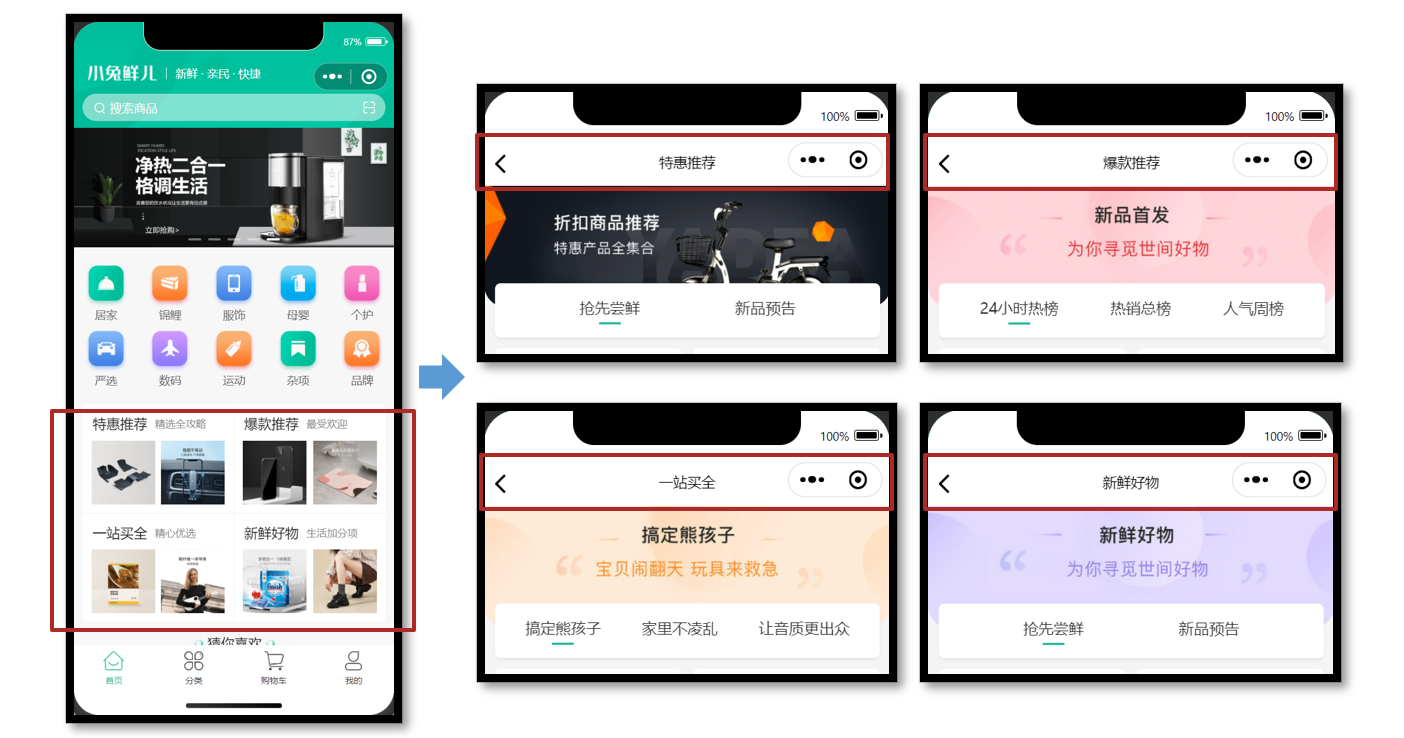


### 创建页面并注册路由

新建 `src/pages/hot/hot.vue`。原课通过 VS Code 的 uni-app 插件自动添加页面路由；创建后应检查 `src/pages.json` 的 `pages` 数组是否已有该项。

如果尚未注册，把下面这一项合并进已有 `pages` 数组，不覆盖其他页面：


```json
{
  "path": "pages/hot/hot",
  "style": {
    "navigationBarTitleText": "热门推荐"
  }
}
```

这是根据本节页面路径补齐的配置示例。导航栏先使用默认标题，稍后根据 `type` 动态更新。

先准备原课的静态页面结构和完整 SCSS：


```vue
<!-- /src/pages/hot/hot.vue -->
<script setup lang="ts">
// 热门推荐页 标题和url
const hotMap = [
  { type: '1', title: '特惠推荐', url: '/hot/preference' },
  { type: '2', title: '爆款推荐', url: '/hot/inVogue' },
  { type: '3', title: '一站买全', url: '/hot/oneStop' },
  { type: '4', title: '新鲜好物', url: '/hot/new' },
]
</script>

<template>
  <view class="viewport">
    <!-- 推荐封面图 -->
    <view class="cover">
      <image
        src="http://yjy-xiaotuxian-dev.oss-cn-beijing.aliyuncs.com/picture/2021-05-20/84abb5b1-8344-49ae-afc1-9cb932f3d593.jpg"
      ></image>
    </view>
    <!-- 推荐选项 -->
    <view class="tabs">
      <text class="text active">抢先尝鲜</text>
      <text class="text">新品预告</text>
    </view>
    <!-- 推荐列表 -->
    <scroll-view scroll-y class="scroll-view">
      <view class="goods">
        <navigator
          hover-class="none"
          class="navigator"
          v-for="goods in 10"
          :key="goods"
          :url="`/pages/goods/goods?id=`"
        >
          <image
            class="thumb"
            src="https://yanxuan-item.nosdn.127.net/5e7864647286c7447eeee7f0025f8c11.png"
          ></image>
          <view class="name ellipsis">不含酒精，使用安心爽肤清洁湿巾</view>
          <view class="price">
            <text class="symbol">¥</text>
            <text class="number">29.90</text>
          </view>
        </navigator>
      </view>
      <view class="loading-text">正在加载...</view>
    </scroll-view>
  </view>
</template>

<style lang="scss">
page {
  height: 100%;
  background-color: #f4f4f4;
}
.viewport {
  display: flex;
  flex-direction: column;
  height: 100%;
  padding: 180rpx 0 0;
  position: relative;
}
.cover {
  width: 750rpx;
  height: 225rpx;
  border-radius: 0 0 40rpx 40rpx;
  overflow: hidden;
  position: absolute;
  left: 0;
  top: 0;
}
.scroll-view {
  flex: 1;
}
.tabs {
  display: flex;
  justify-content: space-evenly;
  height: 100rpx;
  line-height: 90rpx;
  margin: 0 20rpx;
  font-size: 28rpx;
  border-radius: 10rpx;
  box-shadow: 0 4rpx 5rpx rgba(200, 200, 200, 0.3);
  color: #333;
  background-color: #fff;
  position: relative;
  z-index: 9;
  .text {
    margin: 0 20rpx;
    position: relative;
  }
  .active {
    &::after {
      content: '';
      width: 40rpx;
      height: 4rpx;
      transform: translate(-50%);
      background-color: #27ba9b;
      position: absolute;
      left: 50%;
      bottom: 24rpx;
    }
  }
}
.goods {
  display: flex;
  flex-wrap: wrap;
  justify-content: space-between;
  padding: 0 20rpx 20rpx;
  .navigator {
    width: 345rpx;
    padding: 20rpx;
    margin-top: 20rpx;
    border-radius: 10rpx;
    background-color: #fff;
  }
  .thumb {
    width: 305rpx;
    height: 305rpx;
  }
  .name {
    height: 88rpx;
    font-size: 26rpx;
  }
  .price {
    line-height: 1;
    color: #cf4444;
    font-size: 30rpx;
  }
  .symbol {
    font-size: 70%;
  }
  .decimal {
    font-size: 70%;
  }
}

.loading-text {
  text-align: center;
  font-size: 28rpx;
  color: #666;
  padding: 20rpx 0 50rpx;
}
</style>
```

`hotMap` 保存推荐类型、页面标题和接口路径。静态封面、两个 Tab 和 10 个商品只用于验证布局，下一步换成接口数据。

`viewport` 占满页面并使用纵向 flex 布局；封面绝对定位在顶部，Tabs 显示在封面上方，`scroll-view` 占据剩余空间。后续动态代码替换脚本、模板时，保留这一段样式。


### 获取页面参数并设置标题

02 的 `HotPanel.vue` 已通过导航 URL 传递推荐类型：


```vue
<!-- src/pages/index/components/HotPanel.vue -->
<navigator :url="`/pages/hot/hot?type=${item.type}`">
  …省略  
</navigator>
```

例如 `/pages/hot/hot?type=2` 表示进入爆款推荐。这里的 `type` 是页面查询参数，在推荐页按字符串读取。

推荐页面根据参数查找配置并设置标题：


```vue
<!-- src/pages/hot/hot.vue -->
<script setup lang="ts">
// 热门推荐页 标题和url
const hotMap = [
  { type: '1', title: '特惠推荐', url: '/hot/preference' },
  { type: '2', title: '爆款推荐', url: '/hot/inVogue' },
  { type: '3', title: '一站买全', url: '/hot/oneStop' },
  { type: '4', title: '新鲜好物', url: '/hot/new' },
]
// uniapp 获取页面参数
const query = defineProps<{
  type: string
}>()
// console.log(query)
const currHot = hotMap.find((v) => v.type === query.type)
// 动态设置标题
uni.setNavigationBarTitle({ title: currHot!.title })
</script>
```

`defineProps<{ type: string }>()` 是原课读取 uni-app 页面参数的方式。`hotMap.find` 得到当前推荐项，`uni.setNavigationBarTitle` 更新页面导航标题；稍后使用该项的 `url` 请求数据。

> **代码边界**：`currHot!` 是 TypeScript 的非空断言，只影响类型检查，不会在运行时生成默认值。原课假定入口总是传入 `1` 到 `4` 的有效参数。调试时直接打开此页面，也要携带有效的 `type`。


### 根据推荐类型选择接口

四个接口均使用 `GET`，参数与响应格式一致，差别主要在 URL：

| `type` | 推荐类型 | 接口路径 |
| --- | --- | --- |
| `1` | 特惠推荐 | `/hot/preference` |
| `2` | 爆款推荐 | `/hot/inVogue` |
| `3` | 一站买全 | `/hot/oneStop` |
| `4` | 新鲜好物 | `/hot/new` |

查询参数：

| 参数 | 是否必需 | 默认值 | 用途 |
| --- | --- | --- | --- |
| `subType` | 否 | 不传 | 指定推荐列表 Tab 的 ID |
| `page` | 否 | `1` | 请求页码 |
| `pageSize` | 否 | `10` | 每页商品数量 |

`type` 用来在前端选择推荐接口；`subType` 用来在该接口下选择具体 Tab，两者不是同一个字段。不传 `subType` 时，按原课约定获取全部 Tab 的初始列表。


### 封装通用推荐请求

新建 `src/services/hot.ts`，让调用方传入 URL 和分页参数：

> **原稿补齐**：请求函数使用了 `HotResult`，但省略了它的导入。这里补齐 `@/types/hot` 的类型导入，下面会创建对应文件。


```typescript
import { http } from '@/utils/http'
import type { PageParams } from '@/types/global'
import type { HotResult } from '@/types/hot'

type HotParams = PageParams & {
  /** Tab 项的 id，默认查询全部 Tab 项的第 1 页数据 */
  subType?: string
}
/**
 * 通用热门推荐类型
 * @param url 请求地址
 * @param data 请求参数
 */
export const getHotRecommendAPI = (url: string, data?: HotParams) => {
  return http<HotResult>({
    method: 'GET',
    url,
    data,
  })
}
```

`HotParams = PageParams & { subType?: string }` 用交叉类型组合分页参数和推荐子类 ID。

`http<HotResult>` 的结果仍然带有 01 的响应外层结构，推荐业务数据在 `res.result` 中。把 URL 作为参数，只复用共同请求结构，不改变四类推荐各自的接口地址。


### 提取通用商品类型

商品展示在多个模块都会出现。把字段相同的商品结构提取到 `src/types/global.d.ts`，保留 02 已有的 `PageParams` 和 `PageResult<T>`：


```typescript
// src/types/global.d.ts
/** 通用商品类型 */
export type GoodsItem = {
  /** 商品描述 */
  desc: string
  /** 商品折扣 */
  discount: number
  /** id */
  id: string
  /** 商品名称 */
  name: string
  /** 商品已下单数量 */
  orderNum: number
  /** 商品图片 */
  picture: string
  /** 商品价格 */
  price: number
}
```

猜你喜欢使用的 `GuessItem` 与这个通用类型一致，因此用类型别名复用：

> **原稿位置修正**：讲义把下面的别名写在 `src/services/home.ts`，但 02 的组件和服务都从 `@/types/home` 导入 `GuessItem`。为延续已有导入方式，应在 `src/types/home.d.ts` 中把原 `GuessItem` 对象定义替换为这个别名；其他首页类型保留。


```typescript
// src/types/home.d.ts
import type { GoodsItem } from '@/types/global'

// GuessItem 和 GoodsItem 类型相同
export type GuessItem = GoodsItem
```

`GuessItem = GoodsItem` 只是类型别名，不会在运行时复制或转换商品。已有 `@/types/home` 导入无需改动，也不要同时保留旧的同名类型定义。


### 声明推荐结果和 Tab 数据

新建 `src/types/hot.d.ts`：


```typescript
import type { PageResult, GoodsItem } from './global'

/** 热门推荐 */
export type HotResult = {
  /** id信息 */
  id: string
  /** 活动图片 */
  bannerPicture: string
  /** 活动标题 */
  title: string
  /** 子类选项 */
  subTypes: SubTypeItem[]
}

/** 热门推荐-子类选项 */
export type SubTypeItem = {
  /** 子类id */
  id: string
  /** 子类标题 */
  title: string
  /** 子类对应的商品集合 */
  goodsItems: PageResult<GoodsItem>
}
```

数据层次是：

| 层次 | 内容 |
| --- | --- |
| `HotResult` | 推荐活动 ID、封面、标题和全部子类 |
| `HotResult.subTypes` | Tab 列表 |
| `SubTypeItem` | 某个 Tab 的 ID、标题及商品分页结果 |
| `SubTypeItem.goodsItems` | `PageResult<GoodsItem>` |
| `goodsItems.items` | 当前已取得的商品数组 |

`goodsItems` 自带 `page`、`pages` 和 `pageSize`，所以每个 Tab 可以使用自己的分页状态。标题使用 `hotMap` 的配置，封面和 Tab 数据来自接口。


## 多 Tabs 分页加载

用户切换 Tab 时，要展示该项自己的商品；滚动触底时，只为当前 Tab 追加下一页。不能用一个公共页码推进全部 Tab，否则不同列表的加载进度会互相影响。

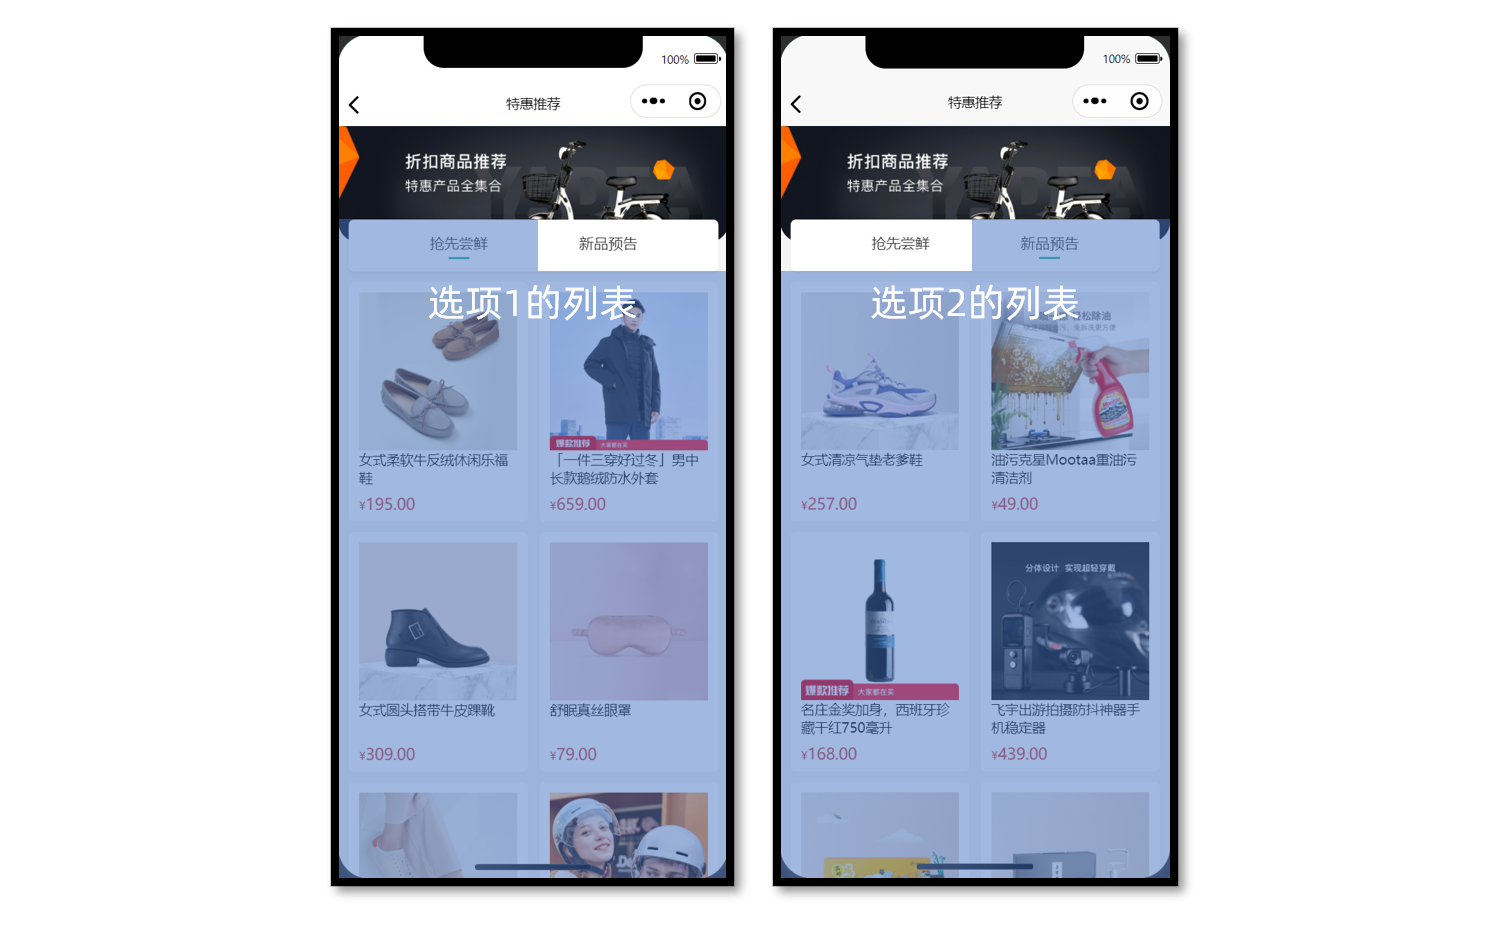


### Tabs 交互基础

在推荐页使用 `activeIndex` 表示当前选中的下标。下面是局部示例，`subTypes` 来自接口；原稿省略了 `ref` 导入，这里补齐：


```vue
<script setup lang="ts">
import { ref } from 'vue'
// 高亮的下标
const activeIndex = ref(0)
</script>

<template>
  <!-- 推荐选项 -->
  <view class="tabs">
    <text
      class="text"
      v-for="(item, index) in subTypes"
      :key="item.id"
      :class="{ active: index === activeIndex }"
      @tap="activeIndex = index"
    >
      {{ item.title }}
    </text>
  </view>
  <!-- 推荐列表 -->
  <scroll-view
    scroll-y
    class="scroll-view"
    v-for="(item, index) in subTypes"
    :key="item.id"
    v-show="activeIndex === index"
  >
    ...省略
  </scroll-view>
</template>
```

点击 Tab 时通过 `@tap` 更新 `activeIndex`，相同下标的标题获得 `active` 类。

列表也遍历 `subTypes`，每个 Tab 对应一个独立的 `scroll-view`，使用 `v-show` 切换可见性。切换时已有列表和滚动容器仍然保留，不会因为销毁再创建而丢失已加载状态。

脚本里更新 ref 使用 `activeIndex.value`；模板中 ref 自动解包，所以可以直接写 `activeIndex = index`。


### 选中 Tab 后如何分页

原课流程：

1. 根据 `activeIndex` 从 `subTypes` 中取得当前 Tab。
2. 查看该 Tab 的 `goodsItems.page` 与 `goodsItems.pages`。
3. 还有下一页时，页码加一。
4. 将当前 Tab 的 `id` 作为 `subType`，携带它自己的页码和每页条数发送请求。
5. 从响应中取得对应 Tab 的商品，用 `push(...新商品)` 追加到已有数组。
6. 到达末页后，把该 Tab 的 `finish` 标记为 `true`，显示结束提示并停止本次请求。

| 状态 | 所在位置 | 作用 |
| --- | --- | --- |
| 选中下标 | 页面 `activeIndex` | 决定当前展示与分页的 Tab |
| 页码 | 每项 `goodsItems.page` | 当前 Tab 的分页进度 |
| 总页数 | 每项 `goodsItems.pages` | 判断是否还有下一页 |
| 已加载商品 | 每项 `goodsItems.items` | 保留并追加商品 |
| 结束标记 | 每项 `finish` | 控制该 Tab 的底部提示 |

原课用 `SubTypeItem & { finish?: boolean }` 给每个 Tab 增加前端状态。`finish` 是可选字段，初始响应中没有它时按未结束显示。


## 参考代码（总）

下面保留原课推荐页的完整脚本与模板。放入 `src/pages/hot/hot.vue`，保留前面静态结构中的 `<style lang="scss">`；不要同时保留两份 `hotMap`、`defineProps` 或脚本。

> **开发测试设置**：原代码使用 `page: import.meta.env.DEV ? 30 : 1`，在开发环境从第 30 页开始，方便测试分页结束。正常跟做首页推荐展示时，把这一行改为 `page: 1`；`30` 是测试值，不是默认首页页码。


```vue
<script setup lang="ts">
import { getHotRecommendAPI } from '@/services/hot'
import type { SubTypeItem } from '@/types/hot'
import { onLoad } from '@dcloudio/uni-app'
import { ref } from 'vue'

// 热门推荐页 标题和url
const hotMap = [
  { type: '1', title: '特惠推荐', url: '/hot/preference' },
  { type: '2', title: '爆款推荐', url: '/hot/inVogue' },
  { type: '3', title: '一站买全', url: '/hot/oneStop' },
  { type: '4', title: '新鲜好物', url: '/hot/new' },
]

// uniapp 获取页面参数
const query = defineProps<{
  type: string
}>()
// 获取当前推荐信息
const currHot = hotMap.find((v) => v.type === query.type)
// 动态设置标题
uni.setNavigationBarTitle({ title: currHot!.title })

// 推荐封面图
const bannerPicture = ref('')
// 推荐选项
const subTypes = ref<(SubTypeItem & { finish?: boolean })[]>([])
// 高亮的下标
const activeIndex = ref(0)
// 获取热门推荐数据
const getHotRecommendData = async () => {
  const res = await getHotRecommendAPI(currHot!.url, {
    // 技巧：环境变量，开发环境，修改初始页面方便测试分页结束
    page: import.meta.env.DEV ? 30 : 1,
    pageSize: 10,
  })
  // 保存封面
  bannerPicture.value = res.result.bannerPicture
  // 保存列表
  subTypes.value = res.result.subTypes
}

// 页面加载
onLoad(() => {
  getHotRecommendData()
})

// 滚动触底
const onScrolltolower = async () => {
  // 获取当前选项
  const currsubTypes = subTypes.value[activeIndex.value]
  // 分页条件
  if (currsubTypes.goodsItems.page < currsubTypes.goodsItems.pages) {
    // 当前页码累加
    currsubTypes.goodsItems.page++
  } else {
    // 标记已结束
    currsubTypes.finish = true
    // 退出并轻提示
    return uni.showToast({ icon: 'none', title: '没有更多数据了~' })
  }

  // 调用API传参
  const res = await getHotRecommendAPI(currHot!.url, {
    subType: currsubTypes.id,
    page: currsubTypes.goodsItems.page,
    pageSize: currsubTypes.goodsItems.pageSize,
  })
  // 新的列表选项
  const newsubTypes = res.result.subTypes[activeIndex.value]
  // 数组追加
  currsubTypes.goodsItems.items.push(...newsubTypes.goodsItems.items)
}
</script>

<template>
  <view class="viewport">
    <!-- 推荐封面图 -->
    <view class="cover">
      <image :src="bannerPicture"></image>
    </view>
    <!-- 推荐选项 -->
    <view class="tabs">
      <text
        v-for="(item, index) in subTypes"
        :key="item.id"
        class="text"
        :class="{ active: index === activeIndex }"
        @tap="activeIndex = index"
        >{{ item.title }}</text
      >
    </view>
    <!-- 推荐列表 -->
    <scroll-view
      v-for="(item, index) in subTypes"
      :key="item.id"
      v-show="activeIndex === index"
      scroll-y
      class="scroll-view"
      @scrolltolower="onScrolltolower"
    >
      <view class="goods">
        <navigator
          hover-class="none"
          class="navigator"
          v-for="goods in item.goodsItems.items"
          :key="goods.id"
          :url="`/pages/goods/goods?id=${goods.id}`"
        >
          <image class="thumb" :src="goods.picture"></image>
          <view class="name ellipsis">{{ goods.name }}</view>
          <view class="price">
            <text class="symbol">¥</text>
            <text class="number">{{ goods.price }}</text>
          </view>
        </navigator>
      </view>
      <view class="loading-text">
        {{ item.finish ? '没有更多数据了~' : '正在加载...' }}
      </view>
    </scroll-view>
  </view>
</template>
```

首次加载在 `onLoad` 执行一次请求，不传 `subType`，取得封面与所有 Tab 的初始数据。点击 Tab 只切换显示；当前代码没有每次切换都重新请求。

触底处理函数选中当前 Tab，并把新增商品追加到该 Tab 的 `goodsItems.items`。商品卡片这次已传入真实的 `goods.id`，导航地址为 `/pages/goods/goods?id=商品ID`；商品详情页面在后续模块实现。


### 对照分页代码时注意的边界

以下是原稿实现本身的条件，便于理解和跟做：

- `res.result.subTypes[activeIndex.value]` 按下标取响应中的 Tab，假定响应数组顺序与当前 Tab 列表一致。使用指定 `subType` 的响应时，应对照实际返回结构确认对应项。
- 请求之前已经保存 `currsubTypes`，但请求之后再次读取 `activeIndex.value`。等待期间切换 Tab，会使两个下标对应不同选项；按 Tab 的 ID 对照响应，才能确认追加的数据属于原先请求的选项。
- 原稿在请求前先增加页码；请求失败后没有回退，下一次触底可能跳过失败的那一页。快速连续触底也没有请求中的标记，可能在上一页未返回时继续发起下一页。
- `finish` 在“再次触底且发现已到末页”时设置，因此最后一页刚返回时，结束提示可能要等下一次触底才出现。底部“正在加载...”是原课显示文案，并不表示此刻一定有请求正在进行。

本篇保留这些原课逻辑，检查分页时应同时观察请求参数、响应 Tab 和追加结果，不能只看商品数量增加。


## 本篇完成检查

- [ ] `pages/hot/hot` 已注册，首页四个入口都传入有效的 `type`。
- [ ] 四类推荐分别使用对应的标题与接口地址。
- [ ] `HotResult` 导入完整，通用商品和分页类型没有重复定义。
- [ ] 正常展示从第 1 页开始，第 30 页只用于开发测试。
- [ ] 切换 Tab 时高亮与商品列表一致，切回后保留已加载内容。
- [ ] 触底请求使用当前 Tab 的 `subType`、`page` 和 `pageSize`。
- [ ] 商品追加到正确的 Tab，其他 Tab 的列表和分页进度不被改动。
- [ ] 到达末页后显示结束提示；检查失败重试和请求期间切换 Tab 的情况。
- [ ] 动态页面仍保留静态阶段的完整 SCSS。

本篇完成推荐页面复用与多个 Tab 的分页展示，衔接 02 的热门推荐入口。
